In [10]:
import numpy as np
import pandas as pd
import spacy

In [11]:
#Read your train and test set
train = pd.read_csv('train_tickets.csv')
test = pd.read_csv('test_tickets.csv')

In [12]:
train

,Unnamed: 0,Description,Class
0,76,"In RGB mode stuck, lightsaber has become. Hmm....",Software issue
1,124,"Broken pc. Hey, last Thursday my pc fell to th...",Purchase requisition
2,5,Ergonomic Chair Purchase. We're running low on...,Purchase requisition
3,116,Privacy glass on the windows. It would be real...,Privacy issue
4,163,Request for updated design software license. T...,Software issue
...,...,...,...
131,104,To many places in the building with cameras. I...,Privacy issue
132,129,Model deployment pipeline fails at Docker buil...,Software issue
133,183,IT Training Request. Requesting training sessi...,Purchase requisition
134,174,Keyboard Not Responding. The printer driver ne...,Software issue


In [13]:
train.drop("Unnamed: 0",axis=1 ,inplace=True)
test.drop("Unnamed: 0",axis=1 ,inplace=True)

C:\Users\Velimir\AppData\Local\Temp\ipykernel_307700\1600316279.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train.drop("Unnamed: 0",axis=1 ,inplace=True)
C:\Users\Velimir\AppData\Local\Temp\ipykernel_307700\1600316279.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test.drop("Unnamed: 0",axis=1 ,inplace=True)


In [14]:
#Get the specific data as informed bellow
X_train = train['Description']
y_train = train['Class']

X_test = test['Description']
y_test = test['Class']

In [15]:
nlp = spacy.load('en_core_web_sm', disable = ['tagger','parser','ner'])

In [16]:
#Create a function to transform tickets in tokens
def ticket_to_tokens(text):
    """Lowercase, tokenize with spaCy, keep only alphabetic non-stopword tokens,
    lemmatize them and return one cleaned string."""
    doc = nlp(str(text).lower())
    tokens = []
    for token in doc:
        if token.is_alpha and not token.is_stop and len(token) > 1:
            lemma = token.lemma_ if token.lemma_ else token.text
            tokens.append(lemma)
    return ' '.join(tokens)

ticket_to_tokens(X_train[1])

c:\Users\Velimir\AppData\Local\Programs\Python\Python313\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)


'broken pc hey thursday pc fell floor wanted know procedure require new sorry inconvenience thanks advance'

In [17]:
from tqdm import tqdm


#Apply the previous function to the X_train

clean_train_tickets = []

#Apply the previous function to the X_train
for ticket in tqdm(X_train):
    clean_train_tickets.append(ticket_to_tokens(ticket))
 

100%|██████████| 136/136 [00:01<00:00, 135.15it/s]


In [18]:
clean_train_tickets

['rgb mode stuck lightsaber hmm problem installing latest security update broken lightsaber longer stable blade rgb mode displays red blue green flashing endlessly balance disco use battle impossible jedi tool toy fix',
 'broken pc hey thursday pc fell floor wanted know procedure require new sorry inconvenience thanks advance',
 'ergonomic chair purchase running low ergonomic chairs office order additional ergonomic chairs improve employee comfort',
 'privacy glass windows nice privacy glasses windows corporate building working street glass wall makes feel uncomfortable',
 'request updated design software license current license design application appears expired preventing file export collaboration kindly initiate renewal process assign active license',
 'cuda cpu use wo work ai training want use gpu check requirements met cuda',
 'replacement malfunctioning input device current keyboard intermittently fails register keystrokes significantly slowing report preparation appreciate repla

In [19]:
from sklearn.feature_extraction.text import CountVectorizer

#Create a CountVectorizer object 
vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 5000)

train_data_features = vectorizer.fit_transform(clean_train_tickets)
train_data_features.shape

(136, 1130)

In [20]:
vocab = vectorizer.get_feature_names_out()
print(vocab)

['ability' 'able' 'academic' ... 'year' 'years' 'yesterday']


In [21]:
train_data_features[0].toarray()

array([[0, 0, 0, ..., 0, 0, 0]], shape=(1, 1130))

In [22]:
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()

classifier.fit(train_data_features, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[45.,38.,53.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.11,-1.28,-0.94]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U20](3,)","['Privacy issue','Purchase requisition','Software issue']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 1130)","[[0.,0.,0.,...,0.,1.,1.], [1.,1.,1.,...,1.,0.,0.], [1.,0.,0.,...,0.,0.,1.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 1130)","[[-7.58,-7.58,-7.58,...,-7.58,-6.89,-6.89], [-6.85,-6.85,-6.85,...,-6.85,-7.54,-7.54], [-6.95,-7.65,-7.65,...,-7.65,-7.65,-6.95]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1130


Preprocess and transform the test set!

In [23]:
clean_test_reviews = []

#perform the data processing in our test set 
for ticket in tqdm(X_test):
    clean_test_reviews.append(ticket_to_tokens(ticket))

# only transform (NOT fit) - the vocabulary must come from the train set
test_data_features = vectorizer.transform(clean_test_reviews)

  0%|          | 0/59 [00:00<?, ?it/s]c:\Users\Velimir\AppData\Local\Programs\Python\Python313\Lib\site-packages\spacy\pipeline\lemmatizer.py:187: UserWarning: [W108] The rule-based lemmatizer did not find POS annotation for one or more tokens. Check that your pipeline includes components that assign token.pos, typically 'tagger'+'attribute_ruler' or 'morphologizer'.
  warnings.warn(Warnings.W108)
100%|██████████| 59/59 [00:00<00:00, 144.00it/s]


In [24]:
clean_test_reviews

['update issues recent update employees experiencing major technical issues recent update older computers especially experiencing issue update devices work correctly',
 'working bored making ticket look busy',
 'customer data sync error customer changed email website update correctly',
 'software update problems requesting update project management software fix bugs improve functionality',
 'request new monitors need purchase new high resolution monitors design team provide quotes specifications monitors meet requirements',
 'unable access corporate vpn dear team currently unable access corporate vpn preventing connecting internal network accessing essential resources investigate issue provide guidance resolve kind regards nelli',
 'lockt locked account password attempts best regards xandress',
 'privacy policy update privacy policy needs updated reflect recent changes data privacy regulations necessary revisions',
 'slow database query standard database queries longer hour complete qu

In [25]:
test_data_features

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 515 stored elements and shape (59, 1130)>

Check your score

In [26]:
#check the score
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", classifier.score(test_data_features, y_test))

Accuracy: 0.7627118644067796


Look at your results and compare with your ground truth

In [27]:
#check the prediction
results = classifier.predict(test_data_features)
print(classification_report(y_test, results))
results

                      precision    recall  f1-score   support

       Privacy issue       0.73      0.79      0.76        14
Purchase requisition       0.68      0.81      0.74        16
      Software issue       0.84      0.72      0.78        29

            accuracy                           0.76        59
           macro avg       0.75      0.77      0.76        59
        weighted avg       0.77      0.76      0.76        59



array(['Software issue', 'Software issue', 'Privacy issue',
       'Software issue', 'Purchase requisition', 'Software issue',
       'Privacy issue', 'Privacy issue', 'Software issue',
       'Purchase requisition', 'Privacy issue', 'Software issue',
       'Purchase requisition', 'Privacy issue', 'Purchase requisition',
       'Privacy issue', 'Privacy issue', 'Purchase requisition',
       'Software issue', 'Purchase requisition', 'Software issue',
       'Software issue', 'Software issue', 'Privacy issue',
       'Software issue', 'Software issue', 'Privacy issue',
       'Purchase requisition', 'Purchase requisition', 'Privacy issue',
       'Software issue', 'Purchase requisition', 'Software issue',
       'Software issue', 'Software issue', 'Purchase requisition',
       'Software issue', 'Purchase requisition', 'Privacy issue',
       'Purchase requisition', 'Purchase requisition',
       'Purchase requisition', 'Software issue', 'Purchase requisition',
       'Software issue',

In [28]:
y_test

0           Software issue
1            Privacy issue
2           Software issue
3           Software issue
4     Purchase requisition
5           Software issue
6           Software issue
7            Privacy issue
8           Software issue
9     Purchase requisition
10           Privacy issue
11    Purchase requisition
12    Purchase requisition
13           Privacy issue
14    Purchase requisition
15           Privacy issue
16           Privacy issue
17    Purchase requisition
18          Software issue
19    Purchase requisition
20          Software issue
21          Software issue
22          Software issue
23    Purchase requisition
24          Software issue
25          Software issue
26           Privacy issue
27    Purchase requisition
28           Privacy issue
29           Privacy issue
30          Software issue
31    Purchase requisition
32    Purchase requisition
33          Software issue
34          Software issue
35          Software issue
36          Software issue
3

Plot a confusion matrix

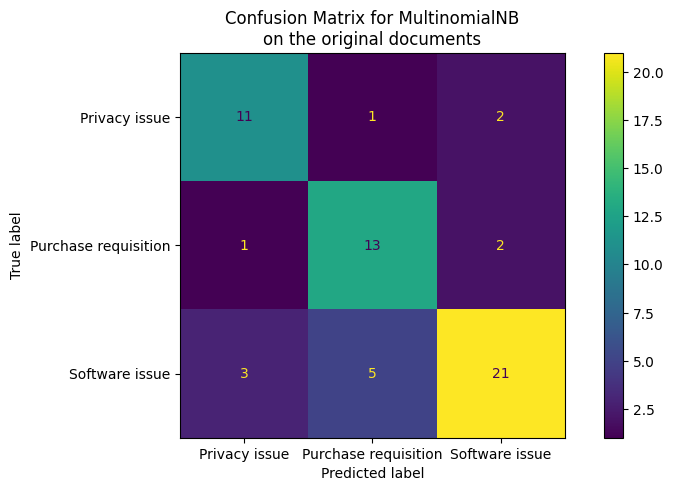

In [29]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

target_names = ['Privacy issue', 'Purchase requisition', 'Software issue']

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, results, ax=ax)
ax.xaxis.set_ticklabels(target_names)
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(f"Confusion Matrix for {classifier.__class__.__name__}\non the original documents")

**Not bad, right?**

Now is your time to play!


---> we use 5000 features, which can consist of unigrams (single words) or bigrams, when using the code below:

vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 5000,
                             ngram_range=(1,2))


What you should do:
- Try to check another parameters, another combination and train your naive bayes model

### Next

Apply other models:
- LogisticRegression
- BernoulliNB
- DecisionTreeClassifier



**Question:** Would you try a Neural Network in this data? Explain your thoughts.

I would not use NNs because there is too little data, hence it is not worth it. Furthurmore, the simpler models do very good and we shouldn't bother to get even better results plus the labels are noisy

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier

vectorizer = CountVectorizer(analyzer='word', max_features=5000)
train_data_features = vectorizer.fit_transform(clean_train_tickets)
test_data_features = vectorizer.transform(clean_test_reviews)

models = {
    "MultinomialNB":  MultinomialNB(),
    "LogisticRegression":     LogisticRegression(max_iter=1000),
    "BernoulliNB":         BernoulliNB(),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=42),
}

model_rows = []
model_preds = {}
for name, model in models.items():
    model.fit(train_data_features, y_train)
    preds = model.predict(test_data_features)
    model_preds[name] = preds
    model_rows.append({"model": name, "accuracy": round(accuracy_score(y_test, preds), 3)})

pd.DataFrame(model_rows).sort_values("accuracy", ascending=False)

,model,accuracy
0,MultinomialNB,0.763
1,LogisticRegression,0.729
3,DecisionTreeClassifier,0.729
2,BernoulliNB,0.695
